# Bluetooth LE: Step-by-Step GFSK Capture Demodulation

This notebook processes the bundled **BLE 1M, 37-byte AA-pattern reference recording** at `captures/tdc_reference_plaintext/BluetoothLe1M/LE1M_AA_37B.txt`. It uses the existing native GFSK receiver, not a newly synthesized waveform or live Bluetooth adapter. A reference recording does not by itself establish measured RF performance.

Run the code cells in order:

1. Load I/Q samples and sample rate, inspect the matching `.para2` inputs, and run native synchronization with the known access-address target `0x71764129`.
2. Plot I/Q and input power with the native burst interval.
3. Plot the complex-baseband spectrum.
4. Compute a phase discriminator, subtract native CFO, and inspect the native frequency-deviation vector separately.
5. Plot nominal two-symbol discriminator overlays and the frequency distribution. For GFSK these are more informative than a QAM constellation.
6. Plot the native 32-bit access-address decisions against the configured target, LSB first.
7. Validate all four bundled BLE 1M recordings, known +35 kHz CFO recovery, and empty-input rejection.

## Settings and Provenance

Change `capture` in the first code cell to another BLE 1M plaintext recording and set the actual `accessAddress` and `modulationIndex`. `load_iq` reads the sample rate from the text header. The default modulation index is 0.5 and nominal symbol rate is 1 Msym/s; nominal deviation is $h R_s / 2 = 250$ kHz. The sidecar's RESULT fields contain unmeasured placeholders and are not used as an accuracy oracle.

The scalar metrics, frequency-deviation vector, and access-address decisions come from the native API. The phase discriminator, nominal eye overlays, spectrum, and bit comparison are notebook diagnostics, not exported internal receiver traces. No absolute capture-time origin is assumed for the native frequency vector. The eye overlays do not establish payload timing or decode payload bits.

## Limits

This walkthrough covers **Bluetooth LE 1M GFSK**, not classic BDR/EDR or LE Coded FEC. Access-address recovery verifies the configured synchronization target; it is not blind address discovery or complete packet decoding. The wrapper does not expose payload dewhitening, PDU parsing, CRC verification, or a decoded payload here. No EVM, BER, instrument accuracy, or Bluetooth RF conformance result is claimed.

In [1]:
%matplotlib inline
import csv
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

if os.name == "nt":
    packages = Path(os.environ["LOCALAPPDATA"]) / "Microsoft" / "WinGet" / "Packages"
    for runtime_dir in packages.glob("BrechtSanders.WinLibs.POSIX.UCRT_*/mingw64/bin"):
        os.environ["PATH"] = str(runtime_dir) + os.pathsep + os.environ.get("PATH", "")
root = next((directory for directory in (Path.cwd(), *Path.cwd().parents)
             if (directory / "nrdemod" / "python" / "nrdemod").is_dir()), None)
if root is None:
    raise FileNotFoundError("Run this notebook from within the nrdemod-vsa workspace")
sys.path.insert(0, str(root / "nrdemod" / "python"))
from nrdemod import demod
from nrdemod.vsa import load_iq

capture = root / "captures/tdc_reference_plaintext/BluetoothLe1M/LE1M_AA_37B.txt"
iq, fs = load_iq(str(capture))
assert fs is not None and fs > 0 and iq.size > 0 and np.isfinite(iq).all()
config = demod.Config(sampleRate=fs, phy=1, modulationIndex=0.5, accessAddress=0x71764129)
result = demod.demodulate(demod.BT_LE, iq, config)
assert result.ok, result.error
print(f"Native demodulator {demod.version()}")
print(f"{capture.name}: {iq.size:,} samples at {fs / 1e6:.3f} MSa/s")
display(result.as_dict())

Native demodulator 1.0.0
LE1M_AA_37B.txt: 6,250 samples at 10.000 MSa/s


{'burstFound': True,
 'syncWordFound': True,
 'burstStart': 24,
 'burstLength': 3860,
 'syncPositionSamples': 136,
 'symbolTimingPhase': 2,
 'syncWordRho': 1.0,
 'frequencyErrorHz': -2.546585164964199e-12,
 'deltaFAvgHz': 149303.64006959373,
 'deltaFMaxHz': 250045.54185601315,
 'deltaFMinHz': 2.546585164964199e-12,
 'samplesPerSymbol': 10.0,
 'ok': True,
 'error': '',
 'family': 'BluetoothLE'}

{'ExitOnPulseSearchFail': '0',
 'LimitSyncWordSearchWindowToStandard': '0',
 'MaximumTimeToSearchForSync': '-999.900024',
 'AntiAliasingFilterEnable': '0',
 'BurstSearchThreshold': '-15.000000',
 'DataPattern': '2',
 'DeltaFMaxThresholdFrequency': '185000.000000',
 'F0CalculationMethod': '1',
 'FrequencyDriftEnable': '1',
 'IcftEnable': '1',
 'LeastRhoForSyncWordDetection': '0.850000',
 'MirrorFrequencySpectrum': '0',
 'ModulationIndex': '0.500000',
 'OffsetAfterPulseFound': '0',
 'OffsetSymbols': '0',
 'PacketFormat': '1',
 'ResultLength': '0',
 'SymbolRate': '1000000.000000',
 'SyncMode': '2'}

Sidecar RESULT entries are not used as accuracy references; they contain unmeasured placeholders.
Configured access address: 0x71764129


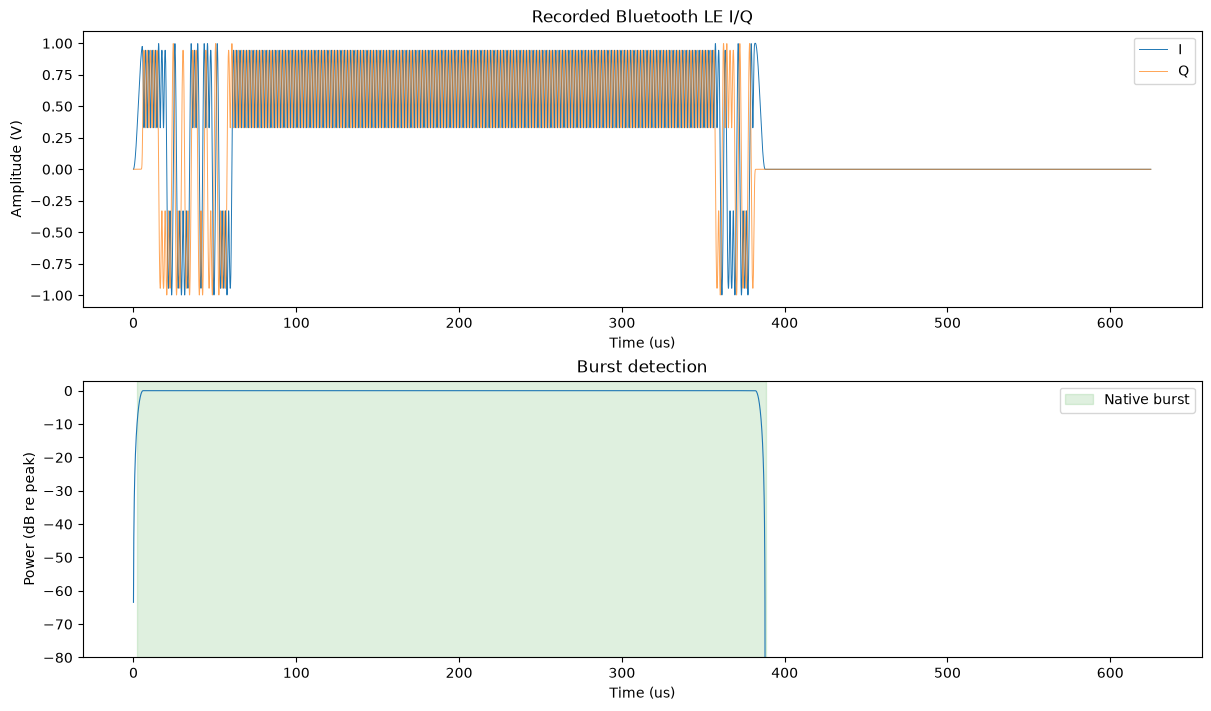

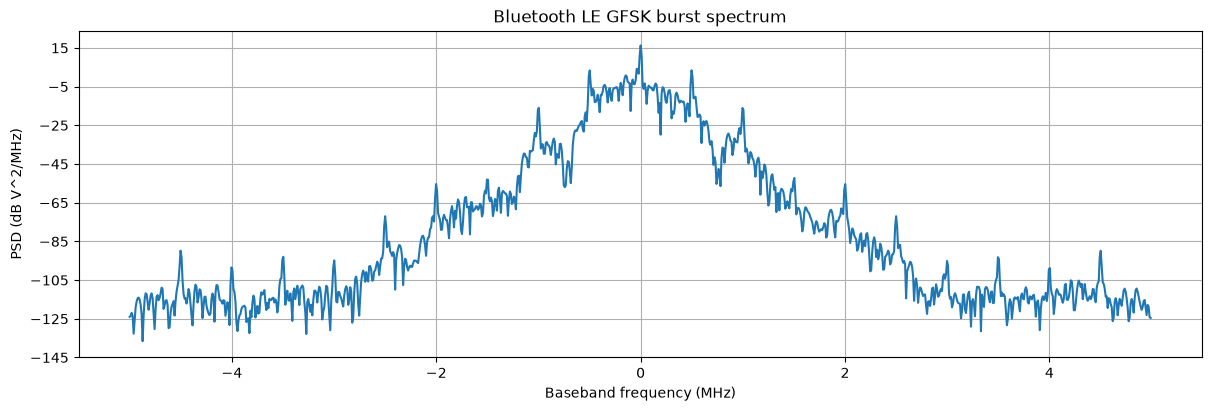

Burst samples [24, 3884); duration 386.000 us


In [2]:
# 1. Inspect the recording's PHY settings and reference provenance.
sidecar = root / "captures/tdc_reference" / capture.parent.name / capture.with_suffix(".para2").name
input_settings = {}
if sidecar.exists():
    with sidecar.open(newline="", encoding="utf-8-sig") as stream:
        for row in csv.reader(stream, skipinitialspace=True):
            if len(row) >= 4 and row[0].strip() == "INPUT":
                input_settings[row[1].strip()] = row[3].strip()
    display(input_settings)
    if "ModulationIndex" in input_settings:
        assert np.isclose(config.modulationIndex, float(input_settings["ModulationIndex"]))
print("Sidecar RESULT entries are not used as accuracy references; they contain unmeasured placeholders.")
print(f"Configured access address: 0x{config.accessAddress:08X}")

# 2. Plot the real I/Q recording and power-detected interval.
time_us = np.arange(iq.size) / fs * 1e6
power = np.abs(iq.astype(np.complex128)) ** 2
power_db = 10 * np.log10(np.maximum(power / power.max(), 1e-12))
burst_start = int(result.burstStart)
burst_end = min(iq.size, burst_start + int(result.burstLength))
assert result.burstFound and 0 <= burst_start < burst_end <= iq.size
figure, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(time_us, iq.real, label="I", linewidth=0.7)
axes[0].plot(time_us, iq.imag, label="Q", linewidth=0.7, alpha=0.7)
axes[0].set(xlabel="Time (us)", ylabel="Amplitude (V)", title="Recorded Bluetooth LE I/Q")
axes[0].legend()
axes[1].plot(time_us, power_db, linewidth=0.8)
axes[1].axvspan(burst_start / fs * 1e6, burst_end / fs * 1e6,
                color="tab:green", alpha=0.15, label="Native burst")
axes[1].set(xlabel="Time (us)", ylabel="Power (dB re peak)", ylim=(-80, 3), title="Burst detection")
axes[1].legend()
plt.show()

# 3. Inspect the complex-baseband spectrum.
figure, axis = plt.subplots(figsize=(12, 4), constrained_layout=True)
axis.psd(iq[burst_start:burst_end], NFFT=1024, Fs=fs / 1e6,
         sides="twosided", scale_by_freq=True)
axis.set(xlabel="Baseband frequency (MHz)", ylabel="PSD (dB V^2/MHz)",
         title="Bluetooth LE GFSK burst spectrum")
plt.show()
print(f"Burst samples [{burst_start}, {burst_end}); duration {(burst_end - burst_start) / fs * 1e6:.3f} us")

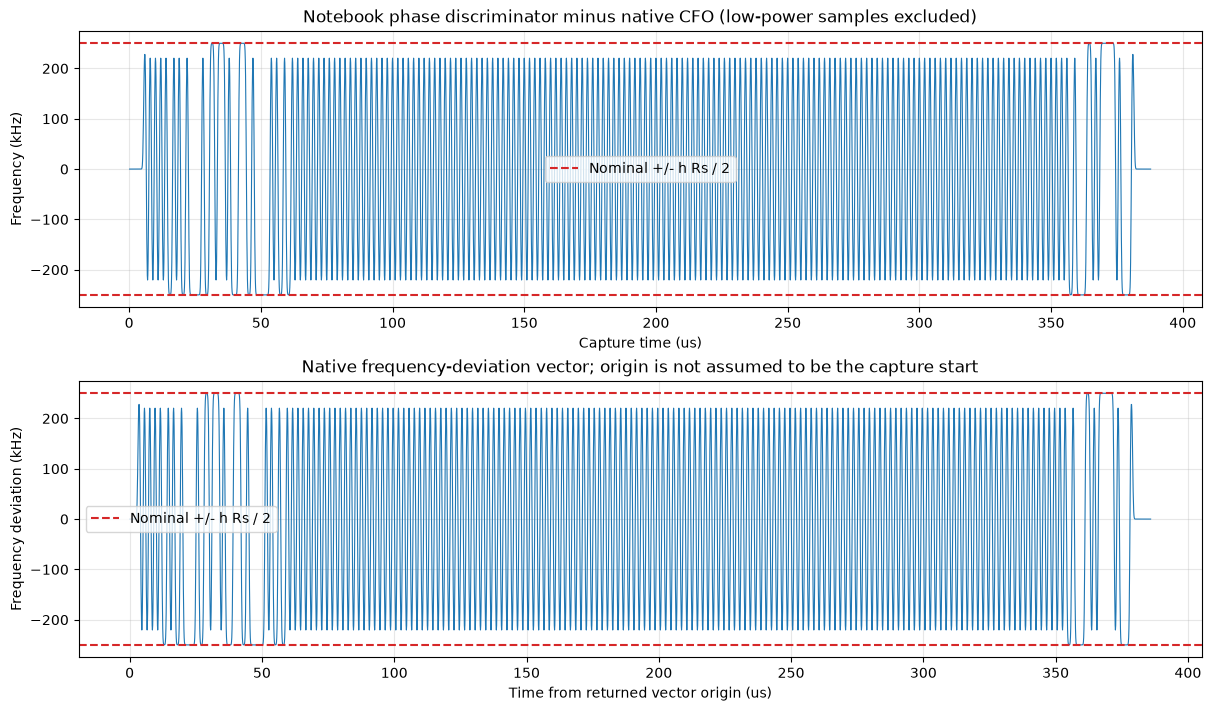

Symbol rate: 1.000 Msym/s; samples per symbol: 10.000
Nominal deviation: +/- 250.000 kHz
Native CFO: -0.000000 Hz; native DeltaF average: 149.304 kHz


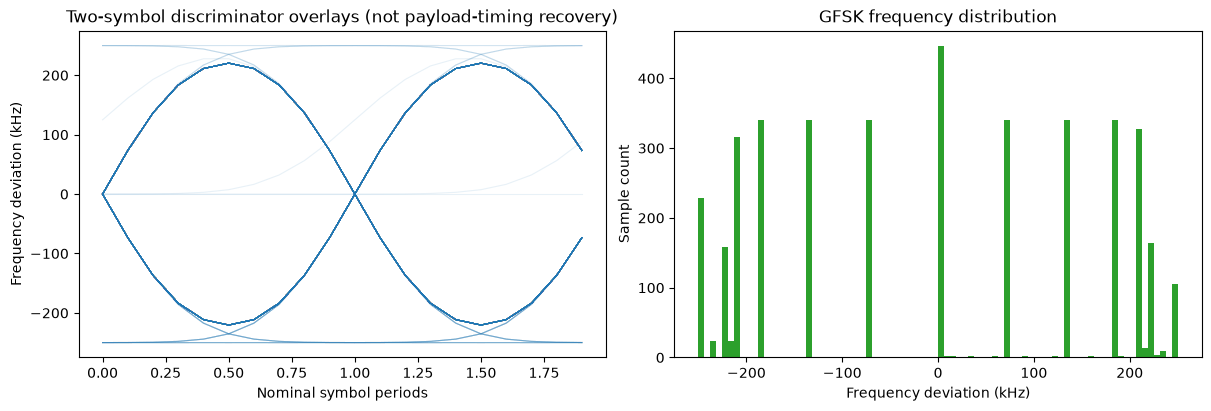

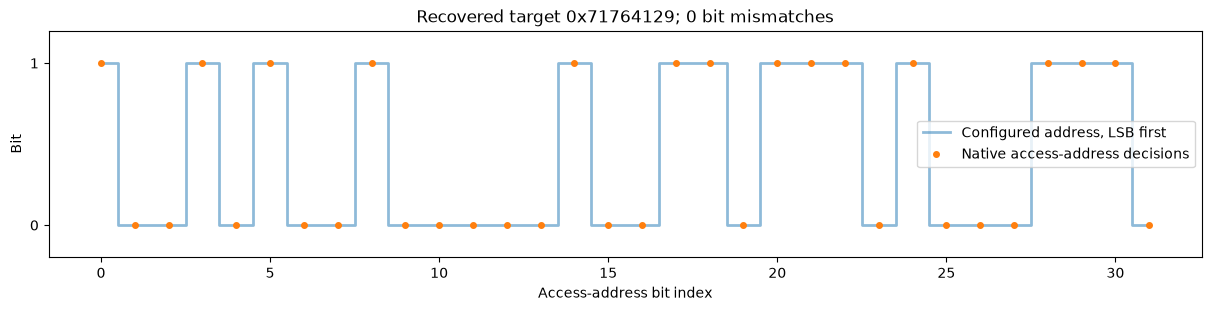

Recovered access address: 0x71764129; sync correlation: 1.000000
Access-address recovery validates the configured synchronization target, not a complete packet.
No payload dewhitening, PDU parsing, CRC verification, or Bluetooth EDR constellation decoding is exposed here.


In [3]:
# 4. Inspect GFSK phase increments and apply the native frequency correction.
samples_per_symbol = float(result.samplesPerSymbol)
symbol_rate = fs / samples_per_symbol
nominal_deviation_hz = config.modulationIndex * symbol_rate / 2
phase_increment = np.angle(iq[1:].astype(np.complex128) * np.conj(iq[:-1]))
instantaneous_hz = phase_increment * fs / (2 * np.pi)
valid = np.minimum(power[1:], power[:-1]) > power.max() * 1e-6
corrected_deviation_hz = np.where(valid, instantaneous_hz - result.frequencyErrorHz, np.nan)
frequency_time_us = np.arange(1, iq.size) / fs * 1e6
native_deviation = result.frequencyDeviationHz
assert native_deviation.size > 0 and np.isfinite(native_deviation).all()
figure, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(frequency_time_us, corrected_deviation_hz / 1e3, linewidth=0.8)
axes[0].set(xlabel="Capture time (us)", ylabel="Frequency (kHz)",
            title="Notebook phase discriminator minus native CFO (low-power samples excluded)")
axes[1].plot(np.arange(native_deviation.size) / fs * 1e6, native_deviation / 1e3, linewidth=0.8)
axes[1].set(xlabel="Time from returned vector origin (us)", ylabel="Frequency deviation (kHz)",
            title="Native frequency-deviation vector; origin is not assumed to be the capture start")
for axis in axes:
    axis.axhline(nominal_deviation_hz / 1e3, color="tab:red", linestyle="--", label="Nominal +/- h Rs / 2")
    axis.axhline(-nominal_deviation_hz / 1e3, color="tab:red", linestyle="--")
    axis.legend()
    axis.grid(True, alpha=0.3)
plt.show()
print(f"Symbol rate: {symbol_rate / 1e6:.3f} Msym/s; samples per symbol: {samples_per_symbol:.3f}")
print(f"Nominal deviation: +/- {nominal_deviation_hz / 1e3:.3f} kHz")
print(f"Native CFO: {result.frequencyErrorHz:.6f} Hz; native DeltaF average: {result.deltaFAvgHz / 1e3:.3f} kHz")

# 5. Overlay nominal symbol windows to inspect Gaussian-shaped transitions.
symbol_samples = int(round(samples_per_symbol))
if not np.isclose(symbol_samples, samples_per_symbol):
    raise ValueError("The eye diagnostic requires an integer number of samples per symbol")
window_length = 2 * symbol_samples
start_indices = np.arange(burst_start, burst_end - window_length, symbol_samples)
segments = np.stack([corrected_deviation_hz[start:start + window_length] for start in start_indices])
figure, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for segment in segments[:200]:
    axes[0].plot(np.arange(window_length) / samples_per_symbol, segment / 1e3,
                 color="tab:blue", alpha=0.1, linewidth=0.8)
axes[0].set(xlabel="Nominal symbol periods", ylabel="Frequency deviation (kHz)",
            title="Two-symbol discriminator overlays (not payload-timing recovery)")
finite_frequency = corrected_deviation_hz[np.isfinite(corrected_deviation_hz)]
axes[1].hist(finite_frequency / 1e3, bins=80, color="tab:green")
axes[1].set(xlabel="Frequency deviation (kHz)", ylabel="Sample count", title="GFSK frequency distribution")
plt.show()

# 6. Compare the native access-address decisions against the configured target.
assert result.syncWordFound, "Set accessAddress to the actual recording's synchronization target"
received_bits = result.accessAddressBits.astype(int)
expected_bits = np.array([(config.accessAddress >> index) & 1 for index in range(32)])
assert received_bits.shape == (32,) and np.isin(received_bits, [0, 1]).all()
received_address = sum(int(bit) << index for index, bit in enumerate(received_bits))
bit_mismatches = int(np.count_nonzero(received_bits != expected_bits))
figure, axis = plt.subplots(figsize=(12, 3), constrained_layout=True)
axis.step(np.arange(32), expected_bits, where="mid", label="Configured address, LSB first", linewidth=2, alpha=0.5)
axis.plot(np.arange(32), received_bits, "o", markersize=4, label="Native access-address decisions")
axis.set(xlabel="Access-address bit index", ylabel="Bit", yticks=[0, 1], ylim=(-0.2, 1.2),
         title=f"Recovered target 0x{received_address:08X}; {bit_mismatches} bit mismatches")
axis.legend()
plt.show()
assert bit_mismatches == 0
print(f"Recovered access address: 0x{received_address:08X}; sync correlation: {result.syncWordRho:.6f}")
print("Access-address recovery validates the configured synchronization target, not a complete packet.")
print("No payload dewhitening, PDU parsing, CRC verification, or Bluetooth EDR constellation decoding is exposed here.")

In [4]:
# 7. Validate synchronization on the bundled BLE 1M recordings.
validation_rows = []
for path in sorted(capture.parent.glob("LE1M_*.txt")):
    recording, recording_fs = load_iq(str(path))
    measured = demod.demodulate(demod.BT_LE, recording,
                               demod.Config(sampleRate=recording_fs, phy=1,
                                            modulationIndex=0.5, accessAddress=config.accessAddress))
    assert measured.ok and measured.burstFound and measured.syncWordFound, (path.name, measured.as_dict())
    address = sum(int(bit) << index for index, bit in enumerate(measured.accessAddressBits))
    assert address == config.accessAddress
    validation_rows.append({"capture": path.name, "sync_rho": measured.syncWordRho,
                            "frequency_error_hz": measured.frequencyErrorHz,
                            "access_address": f"0x{address:08X}"})
assert len(validation_rows) == 4

test_shift_hz = 35000.0
shifted_iq = iq * np.exp(2j * np.pi * test_shift_hz * np.arange(iq.size) / fs)
shifted_result = demod.demodulate(demod.BT_LE, shifted_iq, config)
assert shifted_result.ok and shifted_result.syncWordFound
np.testing.assert_allclose(shifted_result.frequencyErrorHz - result.frequencyErrorHz,
                           test_shift_hz, atol=1.0, rtol=0)
np.testing.assert_array_equal(shifted_result.accessAddressBits, result.accessAddressBits)
empty_result = demod.demodulate(demod.BT_LE, np.empty(0, dtype=np.complex64), config)
assert not empty_result.ok

display(validation_rows)
print(f"Passed {len(validation_rows)} real-recording checks, +35 kHz CFO recovery, and empty-input rejection.")
print("These checks validate synchronization and injected CFO recovery, not payload accuracy or instrument parity.")

[{'capture': 'LE1M_AA_255B.txt',
  'sync_rho': 1.0,
  'frequency_error_hz': -2.546585164964199e-12,
  'access_address': '0x71764129'},
 {'capture': 'LE1M_AA_37B.txt',
  'sync_rho': 1.0,
  'frequency_error_hz': -2.546585164964199e-12,
  'access_address': '0x71764129'},
 {'capture': 'LE1M_F0_255B.txt',
  'sync_rho': 1.0,
  'frequency_error_hz': -2.546585164964199e-12,
  'access_address': '0x71764129'},
 {'capture': 'LE1M_F0_37B.txt',
  'sync_rho': 1.0,
  'frequency_error_hz': -2.546585164964199e-12,
  'access_address': '0x71764129'}]

Passed 4 real-recording checks, +35 kHz CFO recovery, and empty-input rejection.
These checks validate synchronization and injected CFO recovery, not payload accuracy or instrument parity.
